# 02 · Manifold — principal-curve trajectory (whole malignant manifold)

Caron 2020's ALL malignant manifold is **non-branching**: a scFates ElPiGraph principal curve fits
robustly as **2 tips / 0 forks** (fold self-approach ratio ~2.9 > 1, fold-free) across Nodes=15/20/30,
while a PPT *tree* only produces branch nodes whose count scales directly with `Nodes`
(5->7->13 as Nodes 100->150->200) - the spurious noise-fitting signature, not a stable bifurcation.
The module geography (from 01) confirms this: Gast and pSom sit at **opposite poles**
(smoothed r=-0.46), so there is no Gast/pSom co-expression hub to diverge into two arms. Fit the
curve, derive the root at the Gast/pSom-high developmental origin, and compute pseudotime.
Deliverable: `manifold.h5ad`, `manifold.pdf`.

In [1]:
import os, sys, glob, warnings
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import scipy.sparse as sp
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata
raw_name = 'Data_' + name.replace('-2','')
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', raw_name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Caron2020_Hematologic-2 | category: Hematologic


### Load processed manifold (modules + house orientation from 01)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
import io, contextlib
from scipy.sparse.csgraph import shortest_path
xy = adata.obsm['X_umap']; c = xy - xy.mean(0); u,s,vt = np.linalg.svd(c, full_matrices=False)
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
print(f'UMAP principal-axis ratio (major/minor singular value): {s[0]/s[1]:.2f}')
print('smoothed module geography:')
for a,b in [('Gast_sm','pSom_sm'),('Gast_sm','Crest_sm'),('pSom_sm','Crest_sm')]:
    print(f'  {a} vs {b}: r = {np.corrcoef(adata.obs[a],adata.obs[b])[0,1]:+.2f}')

whole malignant manifold: 25784 cells on the joint embedding
UMAP principal-axis ratio (major/minor singular value): 1.92
smoothed module geography:
  Gast_sm vs pSom_sm: r = -0.46
  Gast_sm vs Crest_sm: r = -0.20
  pSom_sm vs Crest_sm: r = -0.74


### Confirm non-branching topology — curve (fold-free) vs tree (spurious forks)
A curve's node self-approach ratio > 1 means non-adjacent nodes stay farther apart than adjacent
ones (no fold). The PPT tree's branch-node count rises with `Nodes` - fitting noise, not topology.

In [4]:
def fold_diag(a2):
    B = np.asarray(a2.uns['graph']['B']); F = a2.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med, tips, forks
for Nn in [15, 20, 30]:
    a2 = adata.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(a2, Nodes=Nn, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    sa,tips,forks = fold_diag(a2); print(f'curve N={Nn}: {tips} tips, {forks} forks | self-approach {sa:.2f}')
for Nn,lam,sig in [(100,2000,0.5),(150,1500,0.4),(200,1000,0.3)]:
    a2 = adata.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.tree(a2, method='ppt', Nodes=Nn, ppt_lambda=lam, ppt_sigma=sig, use_rep='X_umap', seed=SEED, plot=False, basis='umap')
    B = np.asarray(a2.uns['graph']['B']); print(f'PPT tree N={Nn}: {int((B.sum(0)==1).sum())} tips, {int((B.sum(0)>=3).sum())} branch nodes (spurious, scales with Nodes)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(adata, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa,tips,forks = fold_diag(adata)
print(f'chosen curve N=20: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, "topology check failed"

curve N=15: 2 tips, 0 forks | self-approach 2.98
curve N=20: 2 tips, 0 forks | self-approach 2.97
curve N=30: 2 tips, 0 forks | self-approach 2.92
PPT tree N=100: 7 tips, 5 branch nodes (spurious, scales with Nodes)
PPT tree N=150: 9 tips, 7 branch nodes (spurious, scales with Nodes)
PPT tree N=200: 15 tips, 13 branch nodes (spurious, scales with Nodes)
chosen curve N=20: 2 tips, 0 forks | fold self-approach ratio = 2.97 (>1 = fold-free)


### Derive the root (data-driven) and pseudotime
The root is the curve tip where Gast+pSom is highest and Crest lowest - the developmental origin.
Along pseudotime Gast falls (rho -0.73), Crest rises to a terminal gradient. Declared caveat: the
axis co-varies with the cell cycle (the blasts proliferate), but the modules themselves are not
cell-cycle-driven (per-cell |r| <= 0.12 from 01).

In [5]:
B = np.asarray(adata.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(adata.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (adata.obs['Gast_sm'][m].mean(), adata.obs['pSom_sm'][m].mean(), adata.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(adata, root); scf.tl.pseudotime(adata, n_map=1, seed=SEED)
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for s_ in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, adata.obs[s_]); print(f'  {s_}: rho={rho:+.3f} p={p:.1e}')
for m,lb_ in [('Crest_sm','Neural-crest'),('pSom_sm','Somitogenesis'),('Gast_sm','Gastrulation')]:
    hi = adata.obs[m] >= adata.obs[m].quantile(0.9)
    print(f'{lb_}-high decile mean pseudotime = {tn[hi.values].mean():.2f}')
cyc = adata.obs['cc_score'].values
print(f'caveat: pseudotime vs cycling score rho = {spearmanr(t, cyc)[0]:+.2f} (cell-cycle-covarying axis; modules themselves cc-independent)')

tip 0: Gast=-0.0106 pSom=-0.0022 Crest=-0.0139
tip 2: Gast=-0.0274 pSom=+0.0077 Crest=-0.0176
derived root = tip 0 (Gast/pSom-high, Crest-low)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=-0.729 p=0.0e+00
  pSom_sm: rho=+0.034 p=4.6e-08
  Crest_sm: rho=+0.317 p=0.0e+00
Neural-crest-high decile mean pseudotime = 0.68
Somitogenesis-high decile mean pseudotime = 0.90
Gastrulation-high decile mean pseudotime = 0.09
caveat: pseudotime vs cycling score rho = +0.67 (cell-cycle-covarying axis; modules themselves cc-independent)


### Verify house orientation is pseudotime-consistent

In [6]:
r = float(np.corrcoef(adata.obsm['X_umap_lin'][:,0], t)[0,1])
if r < 0:
    adata.obsm['X_umap_lin'][:,0] = -adata.obsm['X_umap_lin'][:,0]
    r = float(np.corrcoef(adata.obsm['X_umap_lin'][:,0], t)[0,1])
assert r > 0.5, f'stored orientation not pseudotime-consistent (corr={r:.2f})'
print(f'house orientation (X_umap_lin) corr(x_lin, pseudotime) = {r:+.2f}')

house orientation (X_umap_lin) corr(x_lin, pseudotime) = +0.99


### Save manifold + trajectory figure (deliverable)
House style - `figsize=(3.5,1.5)`, pseudotime left->right (root at left), `size=30`, cividis.

saved manifold.h5ad + manifold.pdf | root tip 0


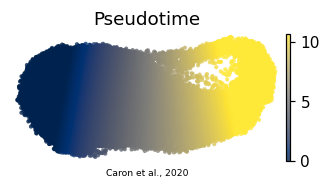

In [7]:
adata.uns['epg'] = {'NodePositions': np.asarray(adata.uns['epg']['NodePositions'])}
adata.write(os.path.join(pth_out, 'manifold.h5ad'))
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Caron et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
plt.show()
print('saved manifold.h5ad + manifold.pdf | root tip', root)